# EDA de variables — competencia_01 (experimento 002)

**Objetivo:** entender qué significa cada familia de variables (en especial las de *fecha en días*), detectar variables "rotas" o que codifican el calendario en vez del cliente, y medir el **drift** del mes a predecir (202108) **sin usar el target**. De acá salen candidatos de transformación que se miden en `run.py` (ΔGanancia en 2 folds).

**Preguntas:**
1. ¿Qué miden `*_Finiciomora`, `*_Fvencimiento`, `*_fultimo_cierre`, `*_fechaalta` y `cliente_antiguedad`, y cómo se comportan mes a mes?
2. ¿Hay valores centinela o artefactos de calendario?
3. ¿Qué tan distinto es 202108 de los meses de entrenamiento (PSI y validación adversarial)?
4. ¿Qué transformaciones valen la pena probar?

Fuente de significados: `docs/diccionario_datos.csv`. Meses disponibles: 202103–202108 (target completo hasta 202106).

In [1]:
import sys, warnings
sys.path.insert(0, '../../src')
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from data import cargar_meses
from drift import tabla_psi, adversarial
from features import fin_de_mes_en_dias

sns.set_theme(style='whitegrid', context='notebook')
pd.set_option('display.width', 200, 'display.max_columns', 30)
MESES = [202103, 202104, 202105, 202106, 202107, 202108]
df = cargar_meses(MESES, solo_con_target=False)
dic = pd.read_csv('../../../docs/diccionario_datos.csv')
ID, MES, TGT = 'numero_de_cliente', 'foto_mes', 'clase_ternaria'
cols = [c for c in df.columns if c not in (ID, MES, TGT)]
df['b2'] = (df[TGT] == 'BAJA+2').astype(float).where(df[TGT].notna())   # NaN donde no hay target
print(df.shape)

(983061, 156)


## 1. Mapa de variables (según el diccionario)

In [2]:
def familia(c):
    if c.startswith('cliente_'): return 'Cliente (edad, antigüedad, vip)'
    if c.startswith('Master_'): return 'Tarjeta Mastercard'
    if c.startswith('Visa_'): return 'Tarjeta Visa'
    if c.startswith('m'): return 'Montos ($)'
    if c.startswith('c'): return 'Cantidades'
    if c.startswith('t'): return 'Flags de adhesión (t*)'
    return 'Otras'
d = dic[dic.campo.isin(cols)].copy()
d['familia'] = d.campo.map(familia)
print(pd.crosstab(d.familia, d.unidad))
print()
print('Variables en días (8):', list(d[d.unidad == 'dias'].campo))

unidad                           --  años  dias  meses  pesos
familia                                                      
Cantidades                       53     0     0      0      0
Cliente (edad, antigüedad, vip)   1     1     0      1      0
Flags de adhesión (t*)            4     0     0      0      0
Montos ($)                        0     0     0      0     44
Otras                             2     0     0      0      0
Tarjeta Mastercard                4     0     4      0     14
Tarjeta Visa                      4     0     4      0     14

Variables en días (8): ['Master_Fvencimiento', 'Master_Finiciomora', 'Master_fultimo_cierre', 'Master_fechaalta', 'Visa_Fvencimiento', 'Visa_Finiciomora', 'Visa_fultimo_cierre', 'Visa_fechaalta']


Dos familias grandes: **montos en pesos** (~73 en el diccionario) y **cantidades/flags** (~68); el resto son 8 variables en **días**, 1 en años, 1 en meses. Los montos están en pesos nominales (inflación: relevante cuando haya más meses). Las columnas `Master_*`/`Visa_*` son nulas si el cliente no tiene esa tarjeta (≈10% y ≈5% de los clientes).

## 2. Variables de fecha en días: ¿son "tiempo transcurrido"?
Para el mismo cliente, ¿cuánto cambia cada variable de un mes al siguiente? Si el evento no cambia, `días desde el evento` avanza 30/31 por mes.

In [3]:
dias = ['Master_fechaalta','Visa_fechaalta','Master_Fvencimiento','Visa_Fvencimiento','Master_Finiciomora','Visa_Finiciomora',
        'Master_fultimo_cierre','Visa_fultimo_cierre','cliente_antiguedad']
sig = {202103:202104, 202104:202105, 202105:202106, 202106:202107, 202107:202108}
a = df[[ID, MES] + dias].copy(); b = a.copy(); b[MES] = b[MES].map({v:k for k,v in sig.items()})
m = a.merge(b.dropna(subset=[MES]).astype({MES:int}), on=[ID, MES], suffixes=('', '_sig'))
filas = []
for v in dias:
    delta = (m[v+'_sig'] - m[v]).where(m[v].notna() & m[v+'_sig'].notna())
    filas.append(delta.groupby(m[MES]).median().rename(v))
tabla = pd.concat(filas, axis=1).T
tabla.columns = [f'{k}->{sig[k]}' for k in tabla.columns]
print('Mediana de (valor mes siguiente - valor este mes), mismo cliente:'); print(tabla)

Mediana de (valor mes siguiente - valor este mes), mismo cliente:
                       202103->202104  202104->202105  202105->202106  202106->202107  202107->202108
Master_fechaalta                 30.0            31.0            30.0            31.0            31.0
Visa_fechaalta                   30.0            31.0            30.0            31.0            31.0
Master_Fvencimiento              30.0            31.0            30.0            31.0            31.0
Visa_Fvencimiento                30.0            31.0            30.0            31.0            31.0
Master_Finiciomora               30.0            31.0            30.0            31.0            31.0
Visa_Finiciomora                 30.0            31.0            30.0            31.0            31.0
Master_fultimo_cierre             1.0             3.0            -5.0             3.0             3.0
Visa_fultimo_cierre               1.0             3.0            -5.0             3.0             3.0
cliente_antigued

**Lectura:**
- `fechaalta`, `Fvencimiento`, `Finiciomora` avanzan exactamente **30/31 días** (los días del mes): miden *tiempo desde un evento fijo*. El evento (fecha de alta de la cuenta, vencimiento del plástico, inicio de la mora) no cambió; lo que cambia es el calendario. `cliente_antiguedad` avanza +1 mes.
- `fultimo_cierre` **no** avanza: salta (+1, +3, −5, +3, +3). Es calendario puro: lo miramos a continuación.
- Una variable que crece con el tiempo hace que un corte del árbol (p. ej. `Master_Finiciomora > 200`) solo exista en meses futuros. Para el rango amplio de `fechaalta` (0–12.000 días) el efecto de 30 días es chico; para `Finiciomora` (0–300) no.

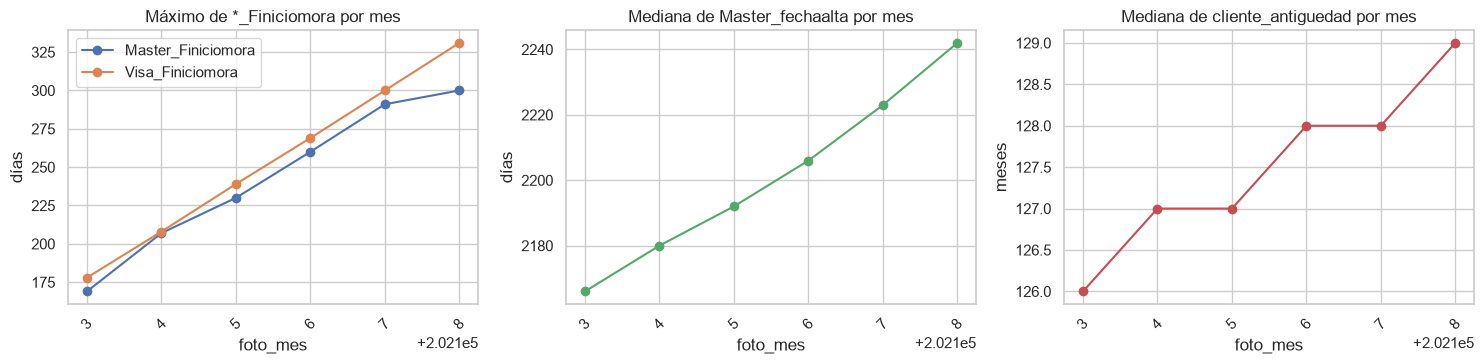

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
mx = df.groupby(MES)[['Master_Finiciomora','Visa_Finiciomora']].max()
mx.plot(ax=ax[0], marker='o'); ax[0].set_title('Máximo de *_Finiciomora por mes'); ax[0].set_ylabel('días')
q = df.groupby(MES)['Master_fechaalta'].median(); q.plot(ax=ax[1], marker='o', color='C2')
ax[1].set_title('Mediana de Master_fechaalta por mes'); ax[1].set_ylabel('días')
df.groupby(MES)['cliente_antiguedad'].median().plot(ax=ax[2], marker='o', color='C3')
ax[2].set_title('Mediana de cliente_antiguedad por mes'); ax[2].set_ylabel('meses')
for x in ax: x.set_xlabel('foto_mes'); x.set_xticks(MESES); x.tick_params(axis='x', rotation=45)
plt.tight_layout(); plt.show()

### 2.1 `Finiciomora`: ¿qué es y cuánta gente la tiene?
99–99.6% de nulos: solo tienen valor los clientes **en mora**. El máximo sube ~30 días por mes (169→207→230→260→291→300): son los mismos clientes morosos envejeciendo.

In [5]:
r = df.groupby(MES).agg(master_con_mora=('Master_Finiciomora', lambda s: s.notna().sum()),
                        visa_con_mora=('Visa_Finiciomora', lambda s: s.notna().sum()))
print(r)

          master_con_mora  visa_con_mora
foto_mes                                
202103               1127           1479
202104                972           1427
202105                818           4344
202106                652            928
202107                685            981
202108                567           4163


## 3. `fultimo_cierre`: una variable de calendario que identifica el mes

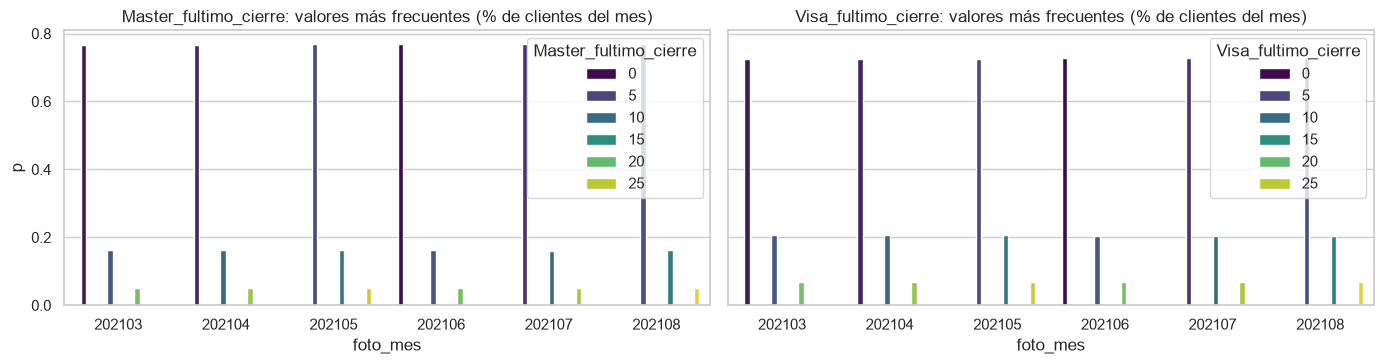

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(14, 3.8), sharey=True)
for x, v in zip(ax, ['Master_fultimo_cierre', 'Visa_fultimo_cierre']):
    t = df[df[v].between(0, 30)].groupby(MES)[v].value_counts(normalize=True).rename('p').reset_index()
    t = t[t.p > 0.03]
    sns.barplot(data=t, x=MES, y='p', hue=v, palette='viridis', ax=x)
    x.set_title(f'{v}: valores más frecuentes (% de clientes del mes)'); x.set_xlabel('foto_mes')
plt.tight_layout(); plt.show()

En cada mes, ~77% de los clientes (Master) tiene **el mismo valor** (ej. 1 en marzo, 2 en abril, 5 en mayo, 0 en junio, 3 en julio, 6 en agosto) y otros dos grupos están a +7 y +21 días: son **ciclos de facturación** (grupos de cierre semanales). Conclusiones:
1. El valor absoluto solo dice *en qué mes estamos* (la fecha de cierre cae distinto cada mes por fin de semana/feriados). Un árbol puede usarlo para separar meses y aprender tasas de baja propias de cada mes: no transfiere a 202108 (valor 6, que no estuvo en ningún mes de train).
2. Lo que sí es información del cliente es **a qué ciclo pertenece**: `valor − moda del mes` ∈ {0, 7, 14, 21,…}. Es estable entre meses.

## 4. Artefacto de mora en Visa (202105 y 202108)

In [7]:
g = df.groupby(MES)
t = pd.DataFrame({
  '% Visa_delinquency=1': g['Visa_delinquency'].mean() * 100,
  '% Master_delinquency=1': g['Master_delinquency'].mean() * 100,
  '% Visa_Finiciomora==0': g['Visa_Finiciomora'].apply(lambda s: (s == 0).mean() * 100),
  '% Visa_Finiciomora>0': g['Visa_Finiciomora'].apply(lambda s: (s > 0).mean() * 100),
}).round(2)
print(t)
art = df[df.Visa_Finiciomora == 0]
print('\nFilas con Visa_Finiciomora==0:', art.groupby(MES).size().to_dict(), '| Visa_delinquency=1 en todas:', (art.Visa_delinquency == 1).all())
tb = pd.DataFrame({
  'Finiciomora==0': art.groupby(MES).b2.mean() * 100,
  'Finiciomora>0 (mora real)': df[df.Visa_Finiciomora > 0].groupby(MES).b2.mean() * 100,
  'Finiciomora nula (sin mora)': df[df.Visa_Finiciomora.isna()].groupby(MES).b2.mean() * 100,
}).round(2)
print('\n% BAJA+2 según estado de mora Visa:'); print(tb)

          % Visa_delinquency=1  % Master_delinquency=1  % Visa_Finiciomora==0  % Visa_Finiciomora>0
foto_mes                                                                                           
202103                    0.95                    0.77                   0.00                  0.91
202104                    0.92                    0.66                   0.00                  0.87
202105                    2.79                    0.56                   1.97                  0.69
202106                    0.59                    0.44                   0.00                  0.57
202107                    0.62                    0.46                   0.00                  0.60
202108                    2.66                    0.38                   1.97                  0.56

Filas con Visa_Finiciomora==0: {202105: 3222, 202108: 3249} | Visa_delinquency=1 en todas: True

% BAJA+2 según estado de mora Visa:
          Finiciomora==0  Finiciomora>0 (mora real)  Finiciomora n

En **202105 y 202108** ~3.200 clientes (2%) aparecen con `Visa_delinquency=1` y `Visa_Finiciomora=0`; en los otros cuatro meses hay **cero**. Su tasa de BAJA+2 (0.81% en 202105) es la de un cliente normal (0.52%) y muy lejos de la de un moroso real (1.4–2.6%): es un **artefacto de calendario** del vencimiento/corte de pagos, no mora. Lo importante para la competencia: **202108 tiene el artefacto** (como 202105, el único mes de entrenamiento que lo tiene).
Master no lo presenta.

## 5. Valores centinela

In [8]:
cent = pd.DataFrame({
  'Master_Fvencimiento < -100000': g['Master_Fvencimiento'].apply(lambda s: (s < -1e5).sum()),
  'Visa_Fvencimiento < -100000': g['Visa_Fvencimiento'].apply(lambda s: (s < -1e5).sum()),
  'Master_fultimo_cierre > 1000': g['Master_fultimo_cierre'].apply(lambda s: (s > 1000).sum()),
  'Visa_fultimo_cierre > 1000': g['Visa_fultimo_cierre'].apply(lambda s: (s > 1000).sum()),
})
print(cent)
print('\nmínimos de Visa_Fvencimiento:', df.Visa_Fvencimiento.nsmallest(3).tolist())

          Master_Fvencimiento < -100000  Visa_Fvencimiento < -100000  Master_fultimo_cierre > 1000  Visa_fultimo_cierre > 1000
foto_mes                                                                                                                      
202103                                0                          466                             0                           0
202104                                0                          463                             1                           0
202105                                0                          458                             0                           1
202106                                0                          454                             0                           0
202107                                0                          449                             1                           1
202108                                1                          446                             0             

`Visa_Fvencimiento ≈ −2.914.000` (≈ −8.000 años) en ~450 clientes por mes: es un código de **"sin fecha"**. Para un árbol es solo un valor muy bajo (inocuo), pero si se calcula una fecha absoluta hay que pasarlo a nulo. Los `fultimo_cierre > 1000` (unas pocas filas) son del mismo tipo.

## 6. Drift de 202108 sin usar el target
**PSI** por variable entre pares de meses (bins por cuantiles del mes de referencia, nulos como bin aparte). Referencia: PSI < 0.1 estable, 0.1–0.25 moderado, > 0.25 importante.

               PSI>0.1  PSI>0.25  máximo
202103→202104        0         0   0.061
202104→202105        0         0   0.064
202105→202106        5         1   0.318
202106→202107        2         0   0.203
202107→202108        0         0   0.070
202106→202108        3         0   0.228
202105→202108        0         0   0.062


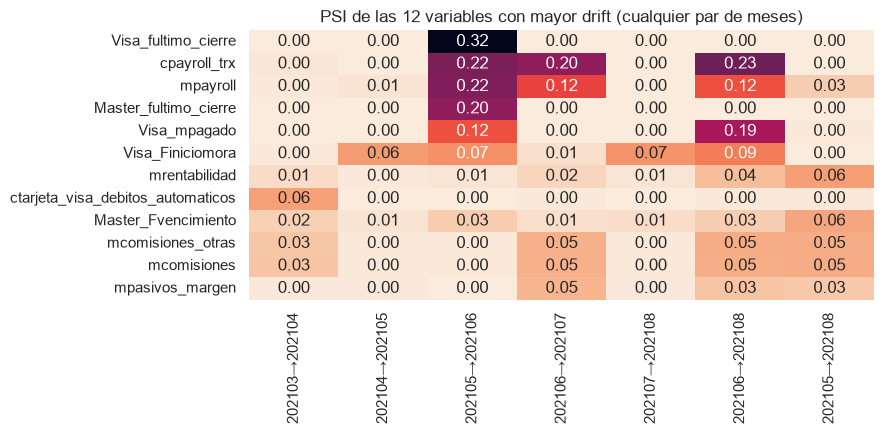

In [9]:
pares = [(202103,202104),(202104,202105),(202105,202106),(202106,202107),(202107,202108),(202106,202108),(202105,202108)]
mes = {k: df[df[MES] == k] for k in MESES}
P = pd.DataFrame({f'{a}→{b}': tabla_psi(mes[a], mes[b], cols) for a, b in pares})
print(pd.DataFrame({'PSI>0.1': (P > 0.1).sum(), 'PSI>0.25': (P > 0.25).sum(), 'máximo': P.max().round(3)}))
top = P.max(axis=1).sort_values(ascending=False).head(12).index
plt.figure(figsize=(9, 4.5)); sns.heatmap(P.loc[top], annot=True, fmt='.2f', cmap='rocket_r', cbar=False)
plt.title('PSI de las 12 variables con mayor drift (cualquier par de meses)'); plt.tight_layout(); plt.show()

**Lectura:** 202108 **no** presenta un drift poblacional grande: entre 202107→202108 ninguna variable supera 0.1, y 202105→202108 tampoco (máx. ≈ 0.06). Los movimientos fuertes están en **junio–julio** (`cpayroll_trx`, `mpayroll`: PSI 0.2–0.3), es decir, en el **mes de validación 202106**: probable efecto estacional (medio aguinaldo, se paga en junio). Cuidado: la ganancia en 202106 puede no ser representativa de agosto.

**Validación adversarial**: un LightGBM intenta distinguir un mes de otro; AUC ≈ 0.5 = indistinguibles. Primero con todas las variables y luego sin las de calendario.

In [10]:
sin_cal = [c for c in cols if c not in dias + ['Master_fechaalta','Visa_fechaalta']]
rows = []
for a_, b_ in [(202104,202106),(202105,202106),(202106,202108),(202105,202108)]:
    auc_t, imp_t = adversarial(mes[a_], mes[b_], cols)
    auc_s, imp_s = adversarial(mes[a_], mes[b_], sin_cal)
    rows.append({'par': f'{a_} vs {b_}', 'AUC (todas)': round(auc_t, 3), 'top (todas)': ', '.join(imp_t.index[:2]),
                 'AUC (sin calendario)': round(auc_s, 3), 'top (sin calendario)': ', '.join(imp_s.index[:3])})
print(pd.DataFrame(rows).to_string(index=False))

             par  AUC (todas)                                top (todas)  AUC (sin calendario)                                                   top (sin calendario)
202104 vs 202106        1.000 Visa_fultimo_cierre, Master_fultimo_cierre                 0.844                      mpayroll, cpayroll_trx, mcomisiones_mantenimiento
202105 vs 202106        0.999 Visa_fultimo_cierre, Master_fultimo_cierre                 0.862              mpayroll, Master_mlimitecompra, mcomisiones_mantenimiento
202106 vs 202108        1.000 Visa_fultimo_cierre, Master_fultimo_cierre                 0.922              mcomisiones_mantenimiento, mpayroll, Master_mlimitecompra
202105 vs 202108        1.000 Visa_fultimo_cierre, Master_fultimo_cierre                 0.907 mcomisiones_mantenimiento, Visa_mconsumosdolares, Master_mlimitecompra


Con todas las variables, **AUC = 1.000**: `Visa_fultimo_cierre` y `Master_fultimo_cierre` (≈ 92–95% de la importancia) identifican el mes perfectamente (y `cliente_antiguedad`, que suma 1 por mes). Sin calendario el AUC baja a ~0.85–0.92: quedan diferencias reales/nominales (nómina, límites de compra, comisiones de mantenimiento).

## 7. Estacionalidad y montos nominales

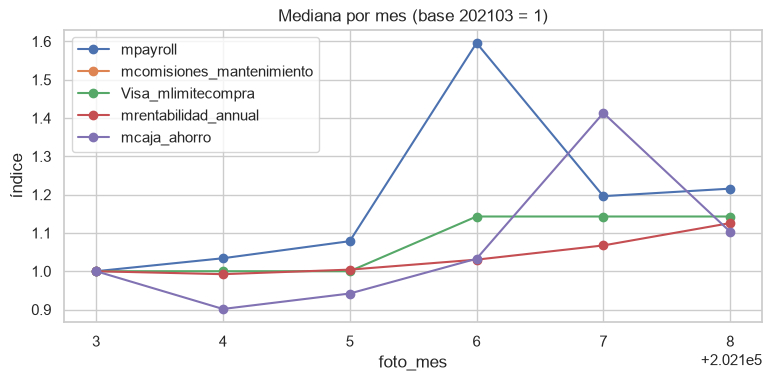

In [11]:
vars_n = ['mpayroll', 'mcomisiones_mantenimiento', 'Visa_mlimitecompra', 'mrentabilidad_annual', 'mcaja_ahorro']
med = df.groupby(MES)[vars_n].median()
med.loc[:, 'mpayroll'] = df[df.mpayroll > 0].groupby(MES).mpayroll.median()     # mediana entre quienes cobran por el banco
(med / med.iloc[0]).plot(figsize=(9, 3.8), marker='o'); plt.title('Mediana por mes (base 202103 = 1)'); plt.ylabel('índice'); plt.xticks(MESES); plt.show()

La nómina (`mpayroll`) salta ~50% en 202106 (probable aguinaldo) y vuelve a la normalidad; el `Visa_mlimitecompra` tiene un escalón en 202106 (actualización de límites). Los montos crecen de forma nominal; con solo 6 meses no hace falta ajustar por inflación (queda para la Última Competencia).

## 8. ¿Qué usa hoy el baseline?

In [12]:
import lightgbm as lgb
from validacion import PARAMS_BASE, xy
tr = df[df[MES].isin([202103, 202104]) & df[TGT].notna()]
X, y = xy(tr.drop(columns='b2'))   # b2 es una columna auxiliar de este notebook: no puede ser feature
imp = pd.concat([pd.Series(lgb.train({**PARAMS_BASE, 'seed': s}, lgb.Dataset(X, label=y), 300).feature_importance('gain'), index=X.columns)
                 for s in [852583, 771227, 676057]], axis=1).mean(axis=1)
imp = (imp / imp.sum()).sort_values(ascending=False)
rank = {v: i + 1 for i, v in enumerate(imp.index)}
print('Top 8:', ', '.join(f'{k} ({v:.3f})' for k, v in imp.head(8).items()))
print('\nVariables de calendario/tiempo transcurrido (puesto de 152, % importancia):')
for v in ['Master_Fvencimiento','Master_fechaalta','Visa_Fvencimiento','Visa_fechaalta','cliente_antiguedad','Master_fultimo_cierre','Visa_fultimo_cierre','Master_Finiciomora','Visa_Finiciomora']:
    print(f'  {v:24s} puesto {rank[v]:3d}   {imp[v]*100:5.2f}%')
print(f'\nVariables con importancia 0: {(imp == 0).sum()} | top-30 acumulan {imp.head(30).sum()*100:.0f}%, top-60 {imp.head(60).sum()*100:.0f}%')

Top 8: ctrx_quarter (0.110), mcaja_ahorro (0.056), mpasivos_margen (0.046), mprestamos_personales (0.033), mcuentas_saldo (0.033), mpayroll (0.032), mrentabilidad_annual (0.026), cpayroll_trx (0.025)

Variables de calendario/tiempo transcurrido (puesto de 152, % importancia):
  Master_Fvencimiento      puesto  14    1.82%
  Master_fechaalta         puesto  15    1.68%
  Visa_Fvencimiento        puesto  20    1.46%
  Visa_fechaalta           puesto  23    1.37%
  cliente_antiguedad       puesto  25    1.29%
  Master_fultimo_cierre    puesto  48    0.55%
  Visa_fultimo_cierre      puesto  59    0.41%
  Master_Finiciomora       puesto  88    0.15%
  Visa_Finiciomora         puesto  89    0.14%

Variables con importancia 0: 5 | top-30 acumulan 70%, top-60 90%


Las variables de tiempo transcurrido (`fechaalta`, `Fvencimiento`, `cliente_antiguedad`) **sí** se usan (puestos 14–25 de 152): no son ruido, pero su valor crudo mezcla "quién es el cliente" con "en qué mes estamos". El baseline está concentrado: 30 variables explican ~70% de la ganancia y 5 tienen importancia 0 (pista para la selección de variables, experimento 004).

## 9. Transformaciones candidatas y su efecto en ganancia
Definidas en `src/features.py`; medidas en `run.py` (5 semillas) y `run_potencia.py` (20 semillas), diferencias pareadas por semilla contra el baseline, `k = 11000`.

In [13]:
from pathlib import Path
for f, t in [('comparacion.csv', '5 semillas'), ('comparacion_20s.csv', '20 semillas')]:
    if Path(f).exists():
        print(f'--- {f} ({t}); deltas en millones, error_std = error estándar de la diferencia media'); print(pd.read_csv(f).to_string(index=False)); print()

--- comparacion.csv (5 semillas); deltas en millones, error_std = error estándar de la diferencia media
             variante  A_gan  A_delta  A_sd_delta  A_auc_delta  B_gan  B_delta  B_sd_delta  B_auc_delta  delta_AB
   V1_cierre_relativo 218.02    -3.08       6.931       -0.001 357.06     2.64      14.164         -0.0     -0.22
  V2_fechas_absolutas 222.42     1.32      16.726       -0.000 367.84    13.42      14.807         -0.0      7.37
    V3_artefacto_visa 220.66    -0.44       1.841        0.000 354.42     0.00       0.000          0.0     -0.22
V4_sin_fultimo_cierre 222.64     1.54      17.967        0.000 357.72     3.30       7.817         -0.0      2.42
          V5_V1+V2+V3 225.28     4.18      15.700       -0.001 357.50     3.08      14.909          0.0      3.63

--- comparacion_20s.csv (20 semillas); deltas en millones, error_std = error estándar de la diferencia media
             variante  A_delta  A_error_std  B_delta  B_error_std  delta_AB
  V2_fechas_absolutas    -

## 10. Conclusiones y decisiones

**Qué aprendimos de los datos**
1. `fechaalta`, `Fvencimiento`, `Finiciomora` y `cliente_antiguedad` son **tiempo transcurrido** desde un evento fijo: avanzan 30/31 días (1 mes) por mes. `Finiciomora` solo la tienen los clientes en mora (≈0.5%) y su máximo crece cada mes.
2. `fultimo_cierre` es **calendario puro** (77% de los clientes comparte valor en cada mes y el valor cambia mes a mes). Identifica el mes con AUC adversarial = 1.0 y en 202108 toma un valor (6) que ningún mes de train tuvo. Lo estable es el *ciclo de facturación* (valor − moda del mes ∈ {0, 7, 21}).
3. **202105 y 202108 comparten un artefacto de Visa**: ~3.200 clientes (2%) con `Visa_delinquency=1` y `Visa_Finiciomora=0`, inexistente en el resto de los meses y sin relación con la baja (BAJA+2 0.81% vs 0.52% de los sin mora y 1.6% de los morosos reales).
4. Hay un centinela "sin fecha" (≈ −2.914.000) en `Visa_Fvencimiento` (~450 clientes/mes).
5. **202108 no tiene drift poblacional importante** (PSI máx. 0.07 contra 202107 y 0.06 contra 202105). El drift fuerte del dataset (nómina, probable aguinaldo) está en **202106**, el mes de validación del fold B: su ganancia (≈360M) no es representativa de un mes "normal" (202105 rinde ≈220M).
6. Las variables de tiempo transcurrido sí tienen peso en el baseline (puestos ~15–40 de 152) y hay 5 variables con importancia 0 (selección de variables: experimento 004).

**Qué probamos (src/features.py) y qué resultó** — ΔGanancia (k=11000) contra el baseline, diferencias pareadas por semilla; con 20 semillas el error estándar de la diferencia es ≈2–4M:

| Variante | Fold A | Fold B | Decisión |
|---|---|---|---|
| V2 fechas absolutas | −0.7 ± 2.4 | −0.4 ± 3.6 | sin efecto |
| V4 sin `fultimo_cierre` | −0.6 ± 2.8 | −4.2 ± 2.3 | no ayuda (levemente peor en B) |
| V5 cierre relativo + fechas abs. + artefacto Visa | +1.6 ± 2.6 | −3.3 ± 3.2 | sin efecto |

**Decisión:** ninguna transformación mejora la ganancia medible. No se adoptan por ahora (se mantienen las variables crudas, que es lo más simple y lo que mejor se defiende). Las funciones quedan en `src/features.py` por si hacen falta (por ejemplo `artefacto_visa` y `cierre_relativo` tienen fundamento por robustez ante 202108, pero la validación no puede verificarlo: ningún fold tiene un train con el artefacto y un valid sin él, ni al revés).

**Lección metodológica importante:** con 5 semillas la variante V2 parecía +13M en el fold B; con 20 semillas es −0.4M. **La ganancia con 5 semillas tiene un ruido de ±4–8M en la media**; el baseline mismo pasa de 354M (5 semillas) a 362M (20 semillas) en el fold B. Para decidir cambios de pocos millones hay que usar ≥ 20 semillas y comparar de a pares.

**Para los próximos experimentos:** (a) validar con 20 semillas antes de aceptar o descartar; (b) tener presente que 202106 es un mes de validación atípico por el aguinaldo; (c) las 10 variables con importancia 0 y las de tiempo transcurrido son candidatas en la selección de variables (004); (d) al construir lags/deltas (003), no usar en los deltas las variables que ya son tiempo transcurrido (su delta es constante: 30/31) ni `fultimo_cierre`.
